# Student Learning Pattern Clustering using Particle Swarm Optimization (PSO)

**Course topic:** Bio-Inspired Computing  |  **Problem 20**

**Goal:** Cluster students using study hours, quiz performance, attendance and assignment completion to discover distinct learning patterns.

### Bio-inspired concept used
**Particle Swarm Optimization (PSO)** — inspired by the social behaviour of bird flocks and fish schools.
Each *particle* is a complete candidate solution (the positions of all `k` cluster centroids). Particles fly through the search space,
pulled toward **their own best position (cognitive term)** and the **swarm's best position (social term)**.

| PSO element | Meaning in this problem |
|---|---|
| Particle | One full set of `k` centroids (a flattened `k × 4` vector) |
| Position | Current centroid locations in the 4-D standardized feature space |
| Velocity | How the centroids move in the next iteration |
| `pbest` / `gbest` | Best centroids found by the particle / by the whole swarm |
| Fitness (minimise) | Mean squared quantization error (average squared distance of each student to the nearest centroid) |

### Pipeline
1. Generate / load student data → 2. EDA → 3. Standardize → 4. **PSO-clustering from scratch** (NumPy) →
5. Auto-select `k` → 6. Convergence & swarm visualisation → 7. Cluster profiling (radar, heatmap, violin) →
8. Compare with K-Means → 9. Stability test → 10. Student-level report & recommendations.

## Setup

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
import warnings; warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook", palette="Set2")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
PALETTE = ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#B279A2", "#9D755D", "#72B7B2", "#FF9DA6"]
FEATURES = ["study_hours", "quiz_score", "attendance", "assignment_completion"]
print("✅ Libraries loaded")

✅ Libraries loaded


## Dataset
We synthesise **400 students** from four hidden learning behaviours (so we can later check how well the swarm recovers them).
The hidden label `true_pattern` is **never used for training**, only for validation at the end.


In [4]:
import numpy as np
import pandas as pd

# Configuration
SEED = 42
USE_OWN_CSV = False

FEATURES = [
    "study_hours",
    "quiz_score",
    "attendance",
    "assignment_completion"
]

def make_students(n_per=(110, 90, 110, 90), seed=SEED):
    rng = np.random.default_rng(seed)

    profiles = {
        "Consistent High Achievers": ([27, 90, 95, 96], [2.5, 4, 3, 3]),
        "Hard Workers": ([22, 55, 82, 78], [3.0, 6, 5, 7]),
        "Smart Skippers": ([8, 82, 58, 52], [2.5, 6, 7, 8]),
        "Disengaged / At-Risk": ([4, 35, 45, 30], [2.0, 6, 8, 8]),
    }

    rows = []

    for (name, (mu, sd)), n in zip(profiles.items(), n_per):
        block = rng.normal(mu, sd, size=(n, 4))
        rows.append(
            pd.DataFrame(block, columns=FEATURES)
            .assign(true_pattern=name)
        )

    df = pd.concat(rows, ignore_index=True)
    df["study_hours"] = df["study_hours"].clip(0, 40)
    df[FEATURES[1:]] = df[FEATURES[1:]].clip(0, 100)

    df = df.sample(frac=1, random_state=seed).reset_index(drop=True)
    df.insert(0, "student_id",
              [f"S{i:03d}" for i in range(1, len(df) + 1)])

    return df.round(1)


# Generate data directly in Colab
df = make_students()

# Save the generated dataset
df.to_csv("students.csv", index=False)

print(f"Shape: {df.shape}")
print(f"Missing values: {int(df[FEATURES].isna().sum().sum())}")

display(df.head(8))
display(df[FEATURES].describe().T.round(2))

Shape: (400, 6)
Missing values: 0


,student_id,study_hours,quiz_score,attendance,assignment_completion,true_pattern
0,S001,7.2,90.6,70.9,49.3,Smart Skippers
1,S002,9.1,82.0,52.8,50.1,Smart Skippers
2,S003,28.6,89.1,90.6,93.0,Consistent High Achievers
3,S004,12.8,82.2,70.3,51.3,Smart Skippers
4,S005,29.1,93.4,96.7,100.0,Consistent High Achievers
5,S006,25.3,91.2,98.5,97.8,Consistent High Achievers
6,S007,3.6,37.3,33.1,39.5,Disengaged / At-Risk
7,S008,26.5,82.0,99.8,94.6,Consistent High Achievers


,count,mean,std,min,25%,50%,75%,max
study_hours,400.0,15.39,9.74,0.0,6.18,13.40,25.00,34.3
quiz_score,400.0,67.13,22.87,17.3,48.25,76.80,87.10,98.9
attendance,400.0,70.27,21.08,26.2,52.35,71.75,91.32,100.0
assignment_completion,400.0,65.01,25.58,14.5,42.98,64.85,92.40,100.0


## Exploratory Data Analysis

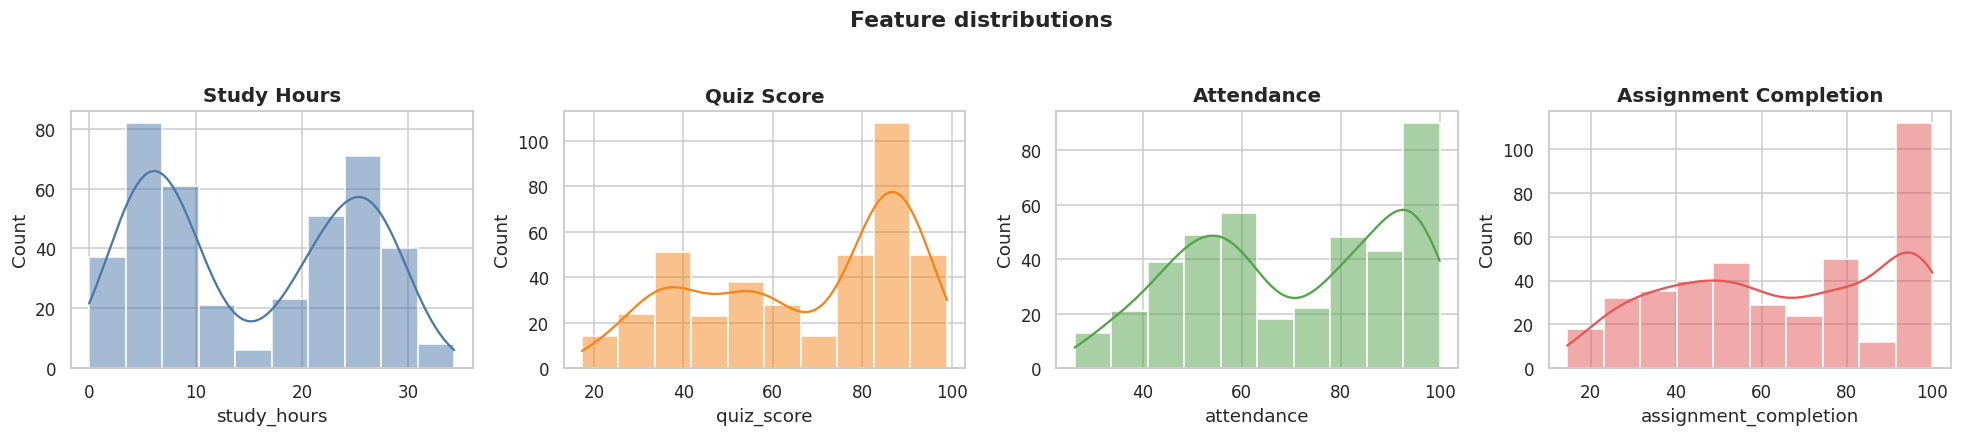

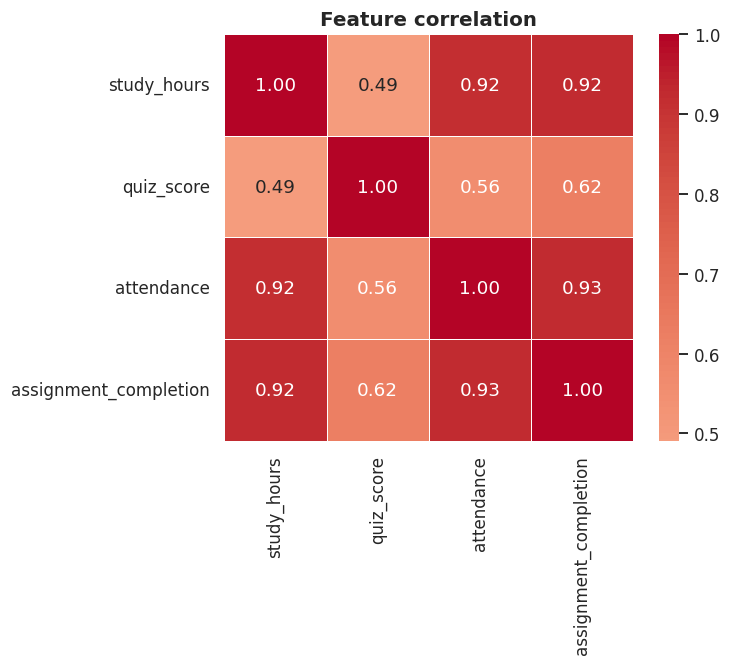

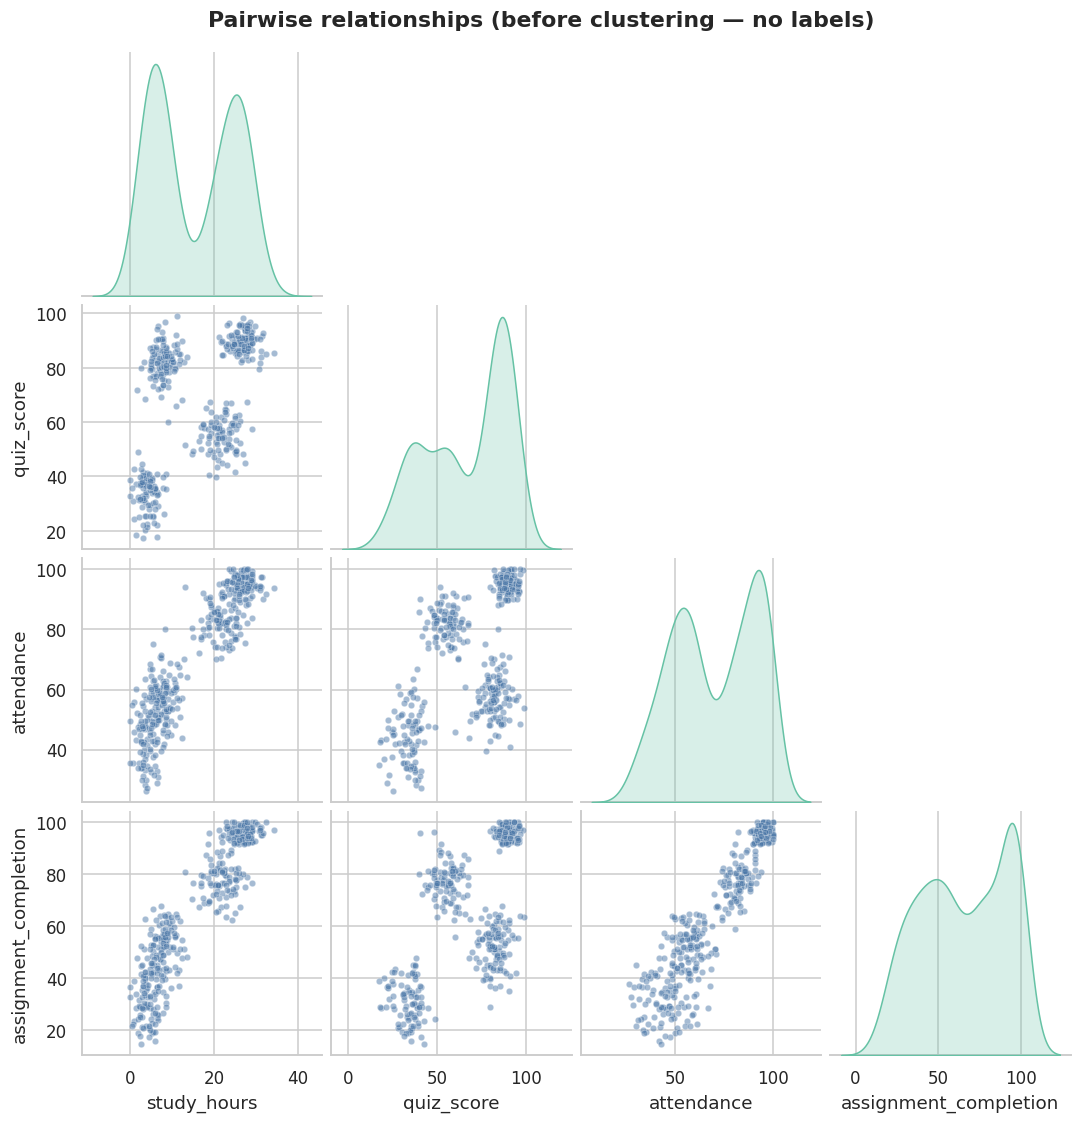

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, f, c in zip(axes, FEATURES, PALETTE):
    sns.histplot(df[f], kde=True, ax=ax, color=c)
    ax.set_title(f.replace("_", " ").title())
plt.suptitle("Feature distributions", fontweight="bold", y=1.04); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6, 4.8))
sns.heatmap(df[FEATURES].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, linewidths=.5)
ax.set_title("Feature correlation"); plt.show()

g = sns.pairplot(df[FEATURES], corner=True, diag_kind="kde", plot_kws=dict(alpha=.5, s=18, color="#4C78A8"))
g.fig.suptitle("Pairwise relationships (before clustering — no labels)", y=1.02, fontweight="bold"); plt.show()

## Pre-processing
Features have different scales (hours vs. percentages) and PSO relies on Euclidean distance, so we **standardize** (z-score).

In [6]:
scaler = StandardScaler()
X = scaler.fit_transform(df[FEATURES].values)
print("Mean ≈", X.mean(0).round(3), "| Std ≈", X.std(0).round(3))
pca = PCA(n_components=2, random_state=SEED).fit(X)
X2 = pca.transform(X)                     # used ONLY for visualisation
print(f"PCA(2D) explains {pca.explained_variance_ratio_.sum()*100:.1f}% of the variance")

Mean ≈ [-0.  0.  0. -0.] | Std ≈ [1. 1. 1. 1.]
PCA(2D) explains 96.5% of the variance


## PSO-based Clustering

**Velocity update**

$$v_{i}^{t+1} = w_t\,v_i^{t} + c_1 r_1 (pbest_i - x_i^{t}) + c_2 r_2 (gbest - x_i^{t}),\qquad x_i^{t+1}=x_i^{t}+v_i^{t+1}$$

**Fitness (to minimise)**

$$J = \frac{1}{N}\sum_{n=1}^{N}\min_{j}\lVert s_n - c_j\rVert^2 \;+\; \text{penalty if any cluster is empty}$$

Enhancements used: **linearly decreasing inertia weight** (explore → exploit), **velocity clamping**, **boundary clipping**,
and **data-point initialisation** of particles for faster convergence.

In [7]:
class PSOClustering:
    '''Particle Swarm Optimisation for centroid-based clustering.'''
    def __init__(self, k, n_particles=40, n_iter=120, w_max=0.9, w_min=0.4,
                 c1=1.7, c2=1.7, vmax_frac=0.25, seed=None):
        self.k, self.P, self.T = k, n_particles, n_iter
        self.w_max, self.w_min, self.c1, self.c2 = w_max, w_min, c1, c2
        self.vmax_frac, self.seed = vmax_frac, seed

    @staticmethod
    def _assign(X, C):
        d = np.linalg.norm(X[:, None, :] - C[None, :, :], axis=2)
        return d.argmin(1), d.min(1)

    def _fitness(self, X, C):
        lab, dmin = self._assign(X, C)
        J = np.mean(dmin ** 2)
        empty = self.k - len(np.unique(lab))
        return J + 10.0 * empty                     # penalise degenerate solutions

    def fit(self, X):
        rng = np.random.default_rng(self.seed)
        N, d = X.shape
        lo, hi = X.min(0), X.max(0)
        vmax = self.vmax_frac * (hi - lo)

        pos = X[rng.integers(0, N, (self.P, self.k))].copy()      # (P, k, d)
        vel = rng.uniform(-vmax, vmax, pos.shape) * 0.1
        pbest = pos.copy()
        pbest_f = np.array([self._fitness(X, p) for p in pos])
        g = pbest_f.argmin(); gbest, gbest_f = pbest[g].copy(), pbest_f[g]

        self.history_best, self.history_mean, self.gbest_history = [], [], []
        self.diversity = []
        for t in range(self.T):
            w = self.w_max - (self.w_max - self.w_min) * t / self.T
            r1, r2 = rng.random(pos.shape), rng.random(pos.shape)
            vel = w * vel + self.c1 * r1 * (pbest - pos) + self.c2 * r2 * (gbest - pos)
            vel = np.clip(vel, -vmax, vmax)
            pos = np.clip(pos + vel, lo, hi)

            f = np.array([self._fitness(X, p) for p in pos])
            better = f < pbest_f
            pbest[better], pbest_f[better] = pos[better], f[better]
            g = pbest_f.argmin()
            if pbest_f[g] < gbest_f: gbest, gbest_f = pbest[g].copy(), pbest_f[g]

            self.history_best.append(gbest_f)
            self.history_mean.append(f.mean())
            self.gbest_history.append(gbest.copy())
            self.diversity.append(pos.reshape(self.P, -1).std(0).mean())   # swarm spread

        self.centroids_, self.best_fitness_ = gbest, gbest_f
        self.labels_, _ = self._assign(X, gbest)
        return self

    def predict(self, X): return self._assign(X, self.centroids_)[0]

# quick sanity test
_t = PSOClustering(k=4, seed=SEED).fit(X)
print("Sanity check → fitness:", round(_t.best_fitness_, 4), "| silhouette:", round(silhouette_score(X, _t.labels_), 4))

Sanity check → fitness: 0.3254 | silhouette: 0.6794


## Choosing the number of clusters (`k`)
For every `k = 2…8` we run PSO and evaluate **four** criteria. The best `k` is chosen by a **rank-aggregation** of the criteria
(more robust than relying on only one metric).

,SSE,Silhouette,Davies_Bouldin,Calinski_Harabasz,Avg_Rank
k,,,,,
2,571.704000,0.566000,0.719000,715.863000,4.667000
3,285.576000,0.611000,0.537000,913.637000,3.333000
4,113.926000,0.679000,0.461000,1721.947000,1.000000
5,102.138000,0.588000,0.822000,1448.393000,3.000000
6,98.630000,0.455000,1.270000,1202.394000,4.667000
7,93.544000,0.348000,1.374000,1066.105000,6.000000
8,92.291000,0.443000,1.247000,922.860000,5.333000


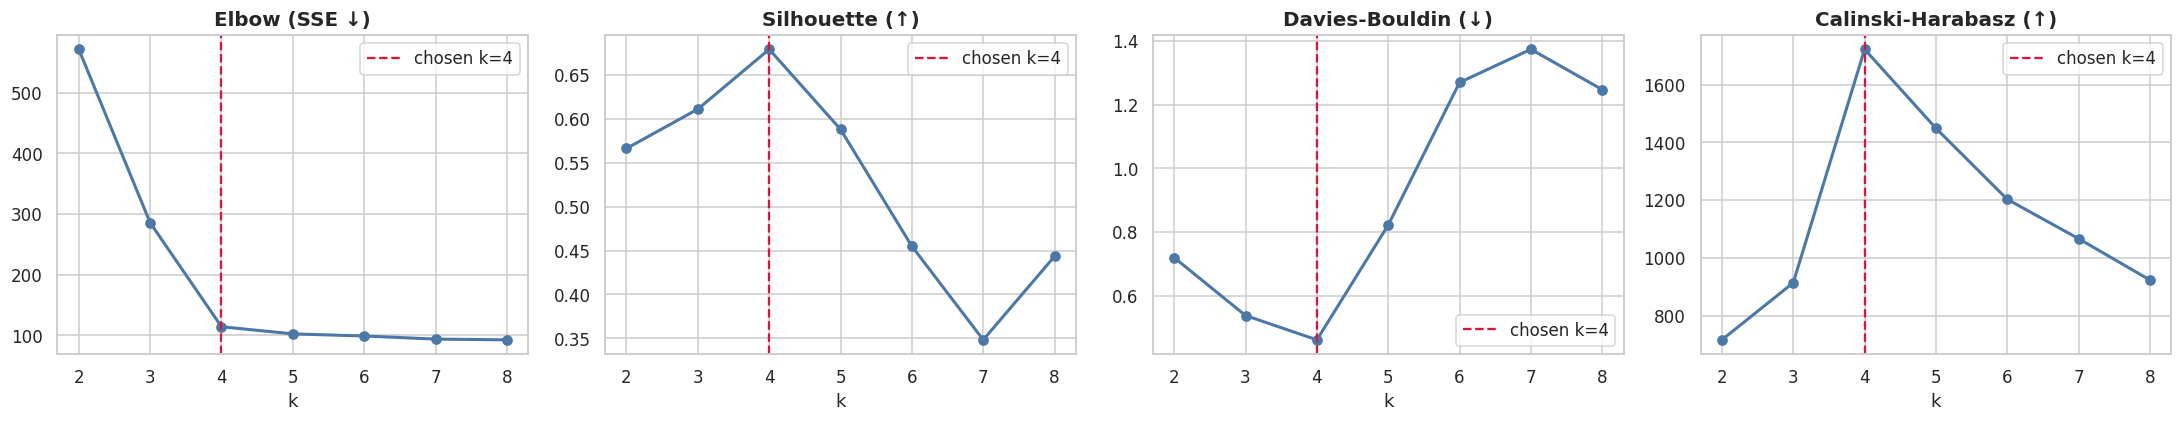


Optimal number of learning patterns: k = 4


In [9]:
K_RANGE = range(2, 9)
rows, models = [], {}
for k in K_RANGE:
    best = min((PSOClustering(k, seed=SEED + r).fit(X) for r in range(3)), key=lambda m: m.best_fitness_)
    models[k] = best
    rows.append(dict(k=k, SSE=best.best_fitness_ * len(X),
                     Silhouette=silhouette_score(X, best.labels_),
                     Davies_Bouldin=davies_bouldin_score(X, best.labels_),
                     Calinski_Harabasz=calinski_harabasz_score(X, best.labels_)))
kdf = pd.DataFrame(rows).set_index("k")

# rank aggregation (lower rank = better)
ranks = pd.DataFrame({"Silhouette": kdf.Silhouette.rank(ascending=False),
                      "Davies_Bouldin": kdf.Davies_Bouldin.rank(ascending=True),
                      "Calinski_Harabasz": kdf.Calinski_Harabasz.rank(ascending=False)})
kdf["Avg_Rank"] = ranks.mean(1)
BEST_K = int(kdf.Avg_Rank.idxmin())
display(kdf.round(3).style.background_gradient(cmap="Greens_r", subset=["Avg_Rank"]))

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
spec = [("SSE", "Elbow (SSE ↓)"), ("Silhouette", "Silhouette (↑)"),
        ("Davies_Bouldin", "Davies-Bouldin (↓)"), ("Calinski_Harabasz", "Calinski-Harabasz (↑)")]
for ax, (col, ttl) in zip(axes, spec):
    ax.plot(kdf.index, kdf[col], "o-", color="#4C78A8", lw=2)
    ax.axvline(BEST_K, color="crimson", ls="--", label=f"chosen k={BEST_K}")
    ax.set_title(ttl); ax.set_xlabel("k"); ax.legend()
plt.tight_layout(); plt.show()
print()
print(f"Optimal number of learning patterns: k = {BEST_K}")

## Final PSO model - convergence and swarm behaviour

Final fitness (MSE) = 0.2848



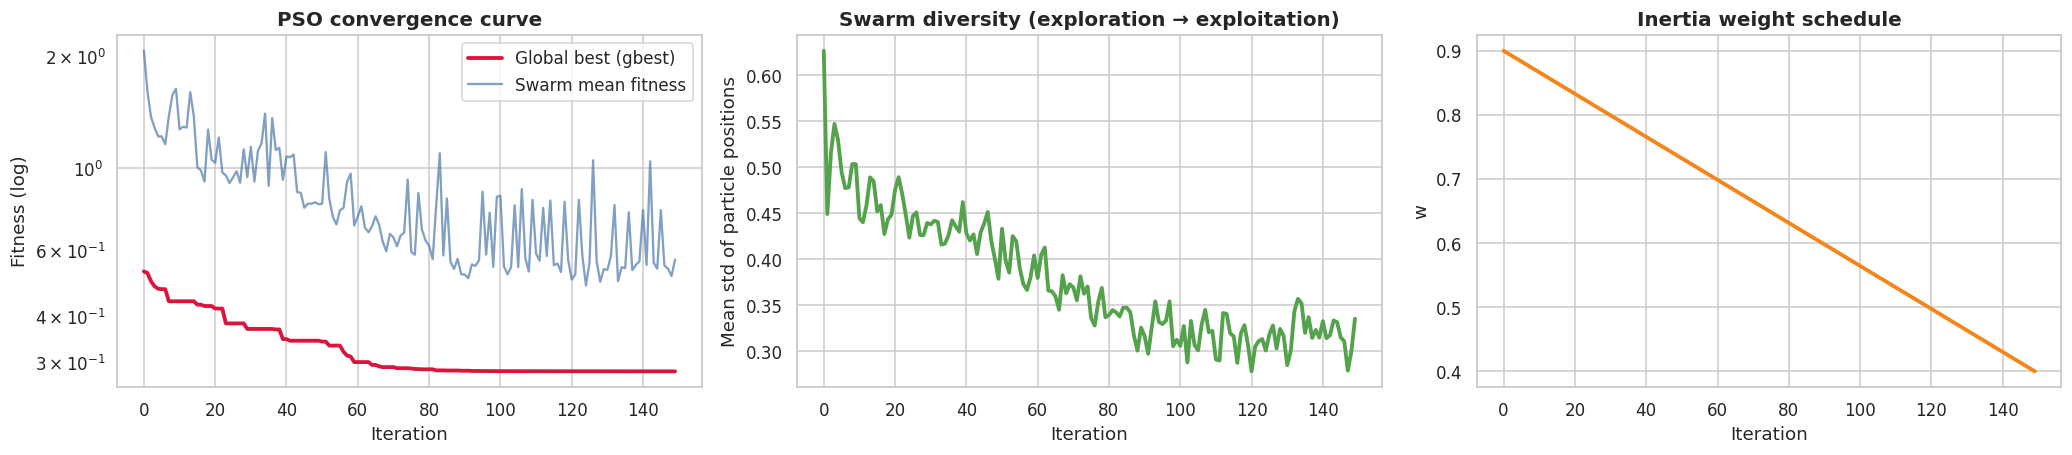

In [10]:
pso = PSOClustering(BEST_K, n_particles=40, n_iter=150, seed=SEED).fit(X)
labels = pso.labels_
print(f"Final fitness (MSE) = {pso.best_fitness_:.4f}")
print()

fig, axes = plt.subplots(1, 3, figsize=(19, 4.3))
axes[0].plot(pso.history_best, color="crimson", lw=2.5, label="Global best (gbest)")
axes[0].plot(pso.history_mean, color="#4C78A8", alpha=.7, label="Swarm mean fitness")
axes[0].set_yscale("log"); axes[0].set_title("PSO convergence curve")
axes[0].set_xlabel("Iteration"); axes[0].set_ylabel("Fitness (log)"); axes[0].legend()

axes[1].plot(pso.diversity, color="#54A24B", lw=2.5)
axes[1].set_title("Swarm diversity (exploration → exploitation)")
axes[1].set_xlabel("Iteration"); axes[1].set_ylabel("Mean std of particle positions")

w = np.linspace(pso.w_max, pso.w_min, pso.T)
axes[2].plot(w, color="#F58518", lw=2.5); axes[2].set_title("Inertia weight schedule")
axes[2].set_xlabel("Iteration"); axes[2].set_ylabel("w")
plt.tight_layout(); plt.show()

### How the swarm discovers the clusters
The plots show how the global-best centroids (⭐) move over different iterations. PCA is used to represent the data in 2D. Initially, the centroids start at different positions and gradually move towards the groups of students.

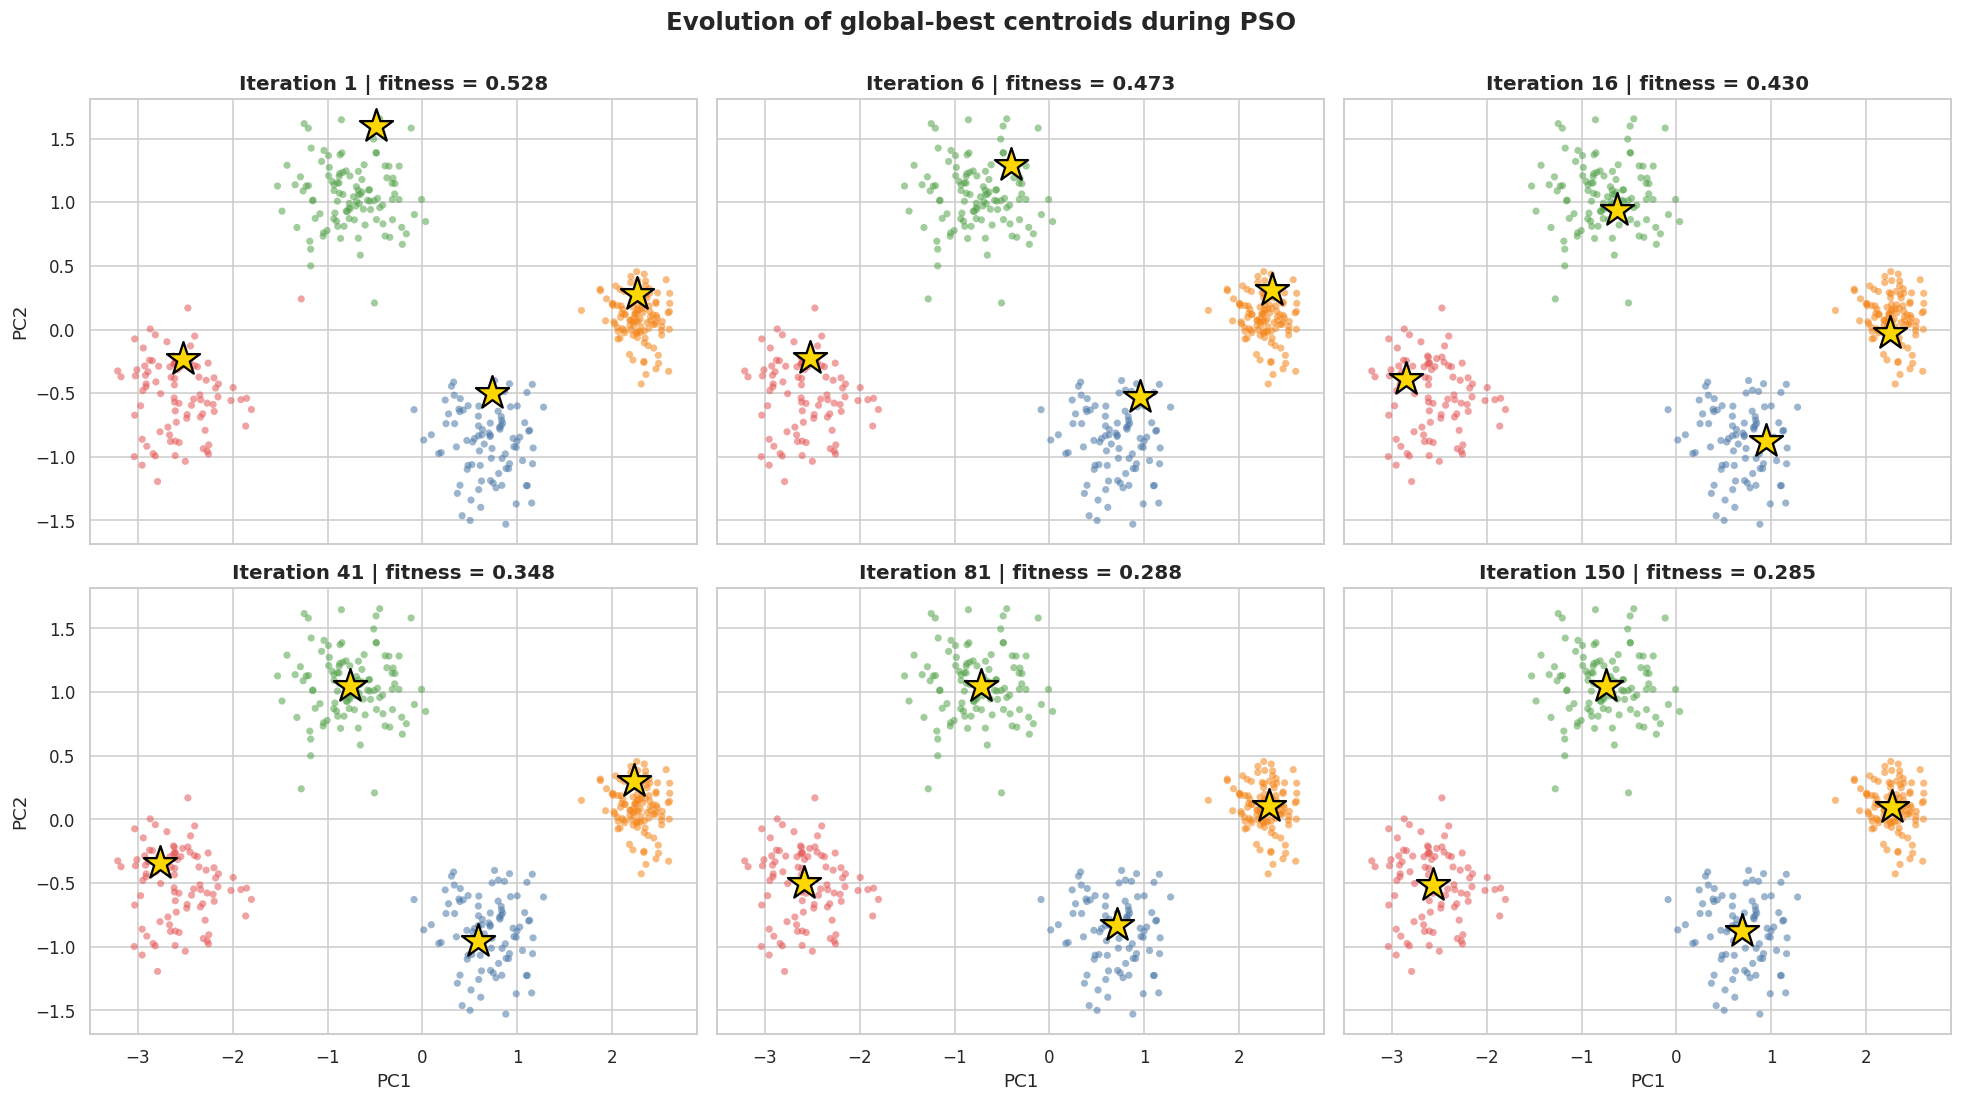

In [11]:
snap_iters = [0, 5, 15, 40, 80, pso.T - 1]
fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex=True, sharey=True)
for ax, it in zip(axes.ravel(), snap_iters):
    C = pso.gbest_history[it]
    lab_it, _ = PSOClustering._assign(X, C)
    ax.scatter(X2[:, 0], X2[:, 1], c=[PALETTE[l % 8] for l in lab_it], s=22, alpha=.55, edgecolor="none")
    C2 = pca.transform(C)
    ax.scatter(C2[:, 0], C2[:, 1], marker="*", s=520, c="gold", edgecolor="black", linewidth=1.5, zorder=5)
    ax.set_title(f"Iteration {it+1} | fitness = {pso.history_best[it]:.3f}")
fig.suptitle("Evolution of global-best centroids during PSO", fontsize=16, fontweight="bold", y=1.0)
for ax in axes[-1]: ax.set_xlabel("PC1")
for ax in axes[:, 0]: ax.set_ylabel("PC2")
plt.tight_layout(); plt.show()

## Final clusters - visualisation

In [12]:
# ---- Auto-name the clusters from their centroid profile (z-scores) ----
Z = pd.DataFrame(pso.centroids_, columns=FEATURES)
def name_cluster(z):
    effort, perf, engage = z.study_hours, z.quiz_score, (z.attendance + z.assignment_completion) / 2
    if perf > .5 and effort > .5:            return "Consistent High Achievers"
    if perf > .3 and effort <= .0:           return "Smart Skippers (efficient / low effort)"
    if effort > .3 and perf <= .3:           return "Hard Workers (need better strategy)"
    if perf < -.5 and engage < -.5:          return "Disengaged / At-Risk"
    return "Moderate Learners"
names, used = {}, {}
for c in range(BEST_K):
    nm = name_cluster(Z.loc[c]); used[nm] = used.get(nm, 0) + 1
    names[c] = nm if used[nm] == 1 else f"{nm} #{used[nm]}"
df["cluster"] = labels
df["pattern"] = df.cluster.map(names)
order = [names[c] for c in range(BEST_K)]
colors = {names[c]: PALETTE[c % 8] for c in range(BEST_K)}
display(df.pattern.value_counts().rename("students").to_frame())

,students
pattern,
Smart Skippers (efficient / low effort),110
Consistent High Achievers,110
Disengaged / At-Risk,90
Hard Workers (need better strategy),90


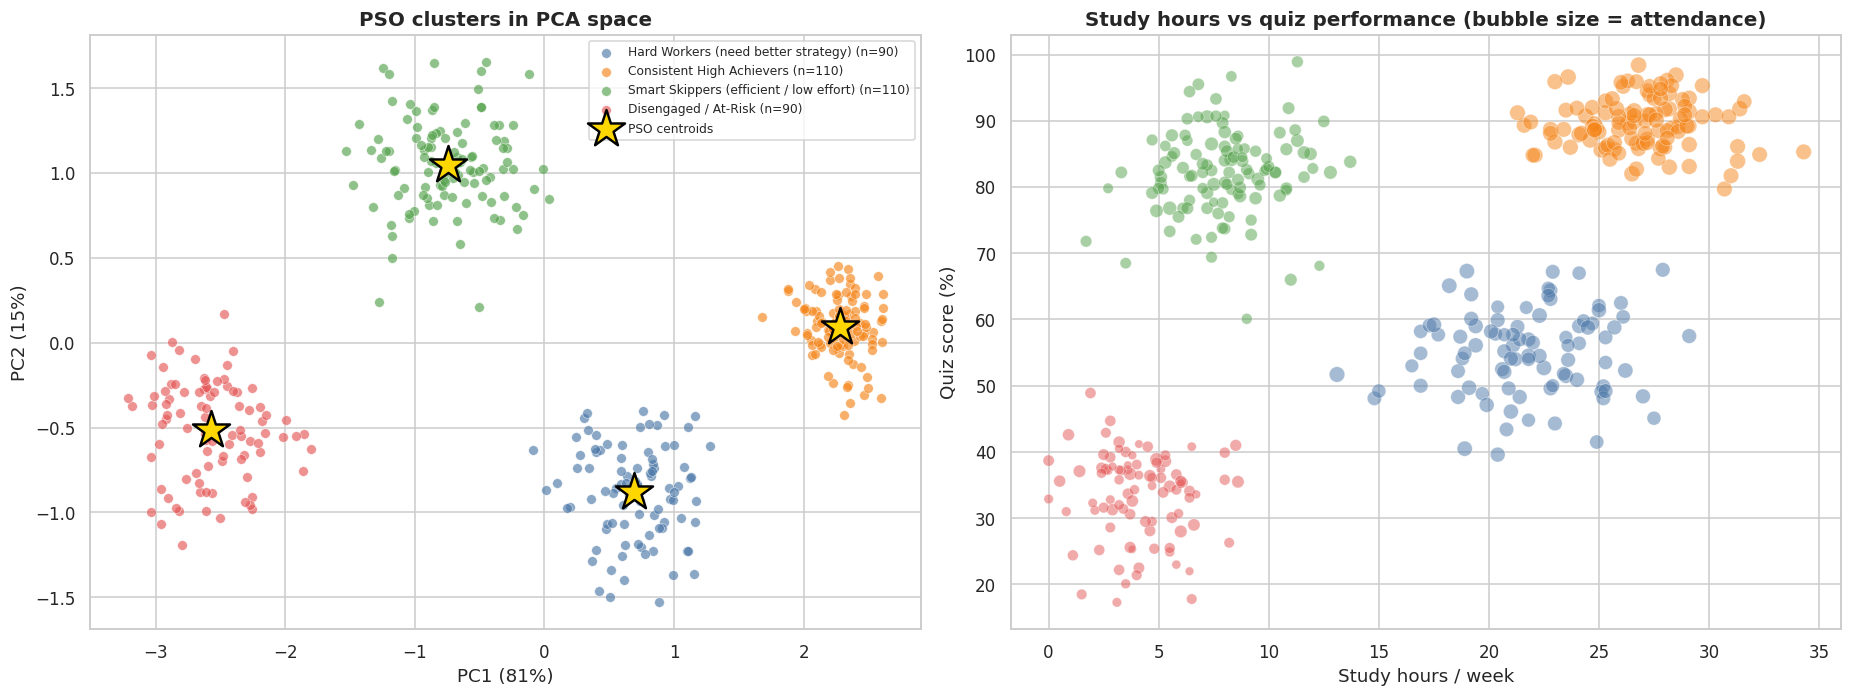

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for nm in order:
    m = df.pattern == nm
    axes[0].scatter(X2[m, 0], X2[m, 1], s=40, alpha=.65, color=colors[nm], label=f"{nm} (n={m.sum()})", edgecolor="white", linewidth=.4)
C2 = pca.transform(pso.centroids_)
axes[0].scatter(C2[:, 0], C2[:, 1], marker="*", s=650, c="gold", edgecolor="black", linewidth=1.6, label="PSO centroids", zorder=5)
axes[0].set_title("PSO clusters in PCA space"); axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.0f}%)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.0f}%)"); axes[0].legend(fontsize=8, loc="best")

# study hours vs quiz, sized by attendance
for nm in order:
    m = df.pattern == nm
    axes[1].scatter(df.study_hours[m], df.quiz_score[m], s=df.attendance[m] * 1.1, alpha=.5, color=colors[nm], edgecolor="white", linewidth=.4)
axes[1].set_xlabel("Study hours / week"); axes[1].set_ylabel("Quiz score (%)")
axes[1].set_title("Study hours vs quiz performance (bubble size = attendance)")
plt.tight_layout(); plt.show()

In [14]:
# ---- Interactive 3-D view (rotate / hover) ----
fig3d = px.scatter_3d(df, x="study_hours", y="quiz_score", z="attendance", color="pattern",
                      size="assignment_completion", size_max=9, opacity=.8, hover_data=["student_id"] + FEATURES,
                      color_discrete_map=colors, title="Interactive 3-D view of learning patterns (size = assignment completion)")
fig3d.update_layout(height=650, legend=dict(orientation="h", y=-0.05)); fig3d.show()

# ---- Parallel coordinates ----
fig_pc = px.parallel_coordinates(df, dimensions=FEATURES, color="cluster",
                                 color_continuous_scale=PALETTE[:BEST_K] if BEST_K > 1 else None,
                                 title="Parallel-coordinates view of all students")
fig_pc.update_layout(height=450); fig_pc.show()

## Cluster profiling - what does each learning pattern look like?

,study_hours,quiz_score,attendance,assignment_completion,students
pattern,,,,,
Hard Workers (need better strategy),21.700000,55.100000,82.100000,77.500000,90
Consistent High Achievers,26.800000,89.600000,95.100000,95.900000,110
Smart Skippers (efficient / low effort),8.000000,82.100000,57.200000,52.000000,110
Disengaged / At-Risk,4.100000,33.500000,44.100000,30.700000,90


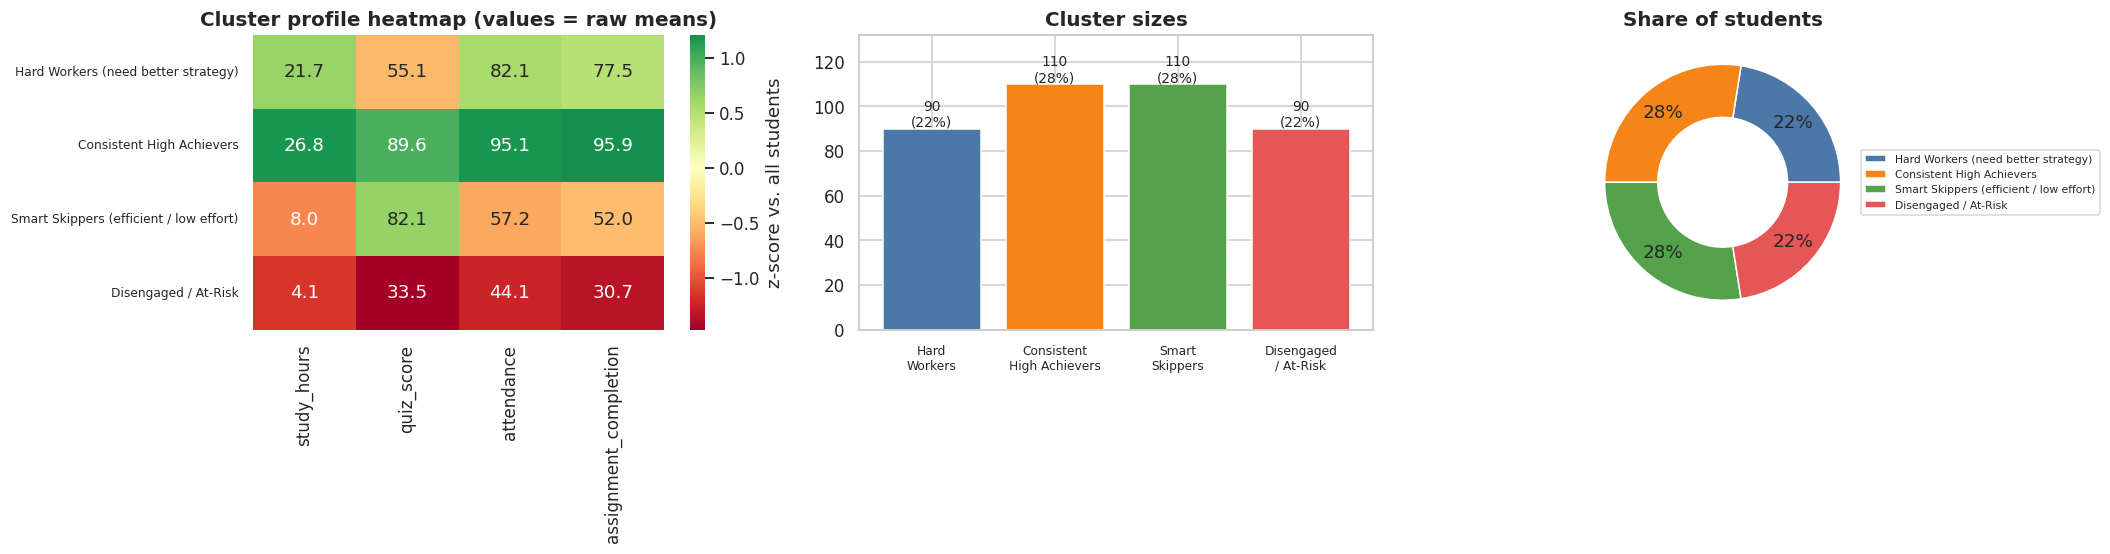

In [15]:
prof = df.groupby("pattern")[FEATURES].mean().loc[order]
prof["students"] = df.pattern.value_counts().loc[order]
display(prof.round(1).style.background_gradient(cmap="YlGnBu", subset=FEATURES))

fig, axes = plt.subplots(1, 3, figsize=(20, 5.2))
# (a) heatmap of z-scores
sns.heatmap(prof[FEATURES].apply(lambda s: (s - df[s.name].mean()) / df[s.name].std()), annot=prof[FEATURES].round(1),
            fmt="", cmap="RdYlGn", center=0, ax=axes[0], cbar_kws={"label": "z-score vs. all students"})
axes[0].set_title("Cluster profile heatmap (values = raw means)"); axes[0].set_ylabel(""); axes[0].tick_params(axis="y", labelsize=8)
# (b) size bar
cnt = df.pattern.value_counts().loc[order]
axes[1].bar(range(len(cnt)), cnt.values, color=[colors[n] for n in order])
axes[1].set_xticks(range(len(cnt))); axes[1].set_xticklabels([n.split(" (")[0].replace(" ", "\n", 1) for n in order], fontsize=8)
for i, v in enumerate(cnt.values): axes[1].text(i, v + 1, f"{v}\n({v/len(df)*100:.0f}%)", ha="center", fontsize=9)
axes[1].set_title("Cluster sizes"); axes[1].set_ylim(0, cnt.max() * 1.2)
# (c) donut
axes[2].pie(cnt.values, labels=None, colors=[colors[n] for n in order], autopct="%1.0f%%", pctdistance=.78,
            wedgeprops=dict(width=.45, edgecolor="white"))
axes[2].legend(order, fontsize=7, loc="center left", bbox_to_anchor=(.95, .5)); axes[2].set_title("Share of students")
plt.tight_layout(); plt.show()

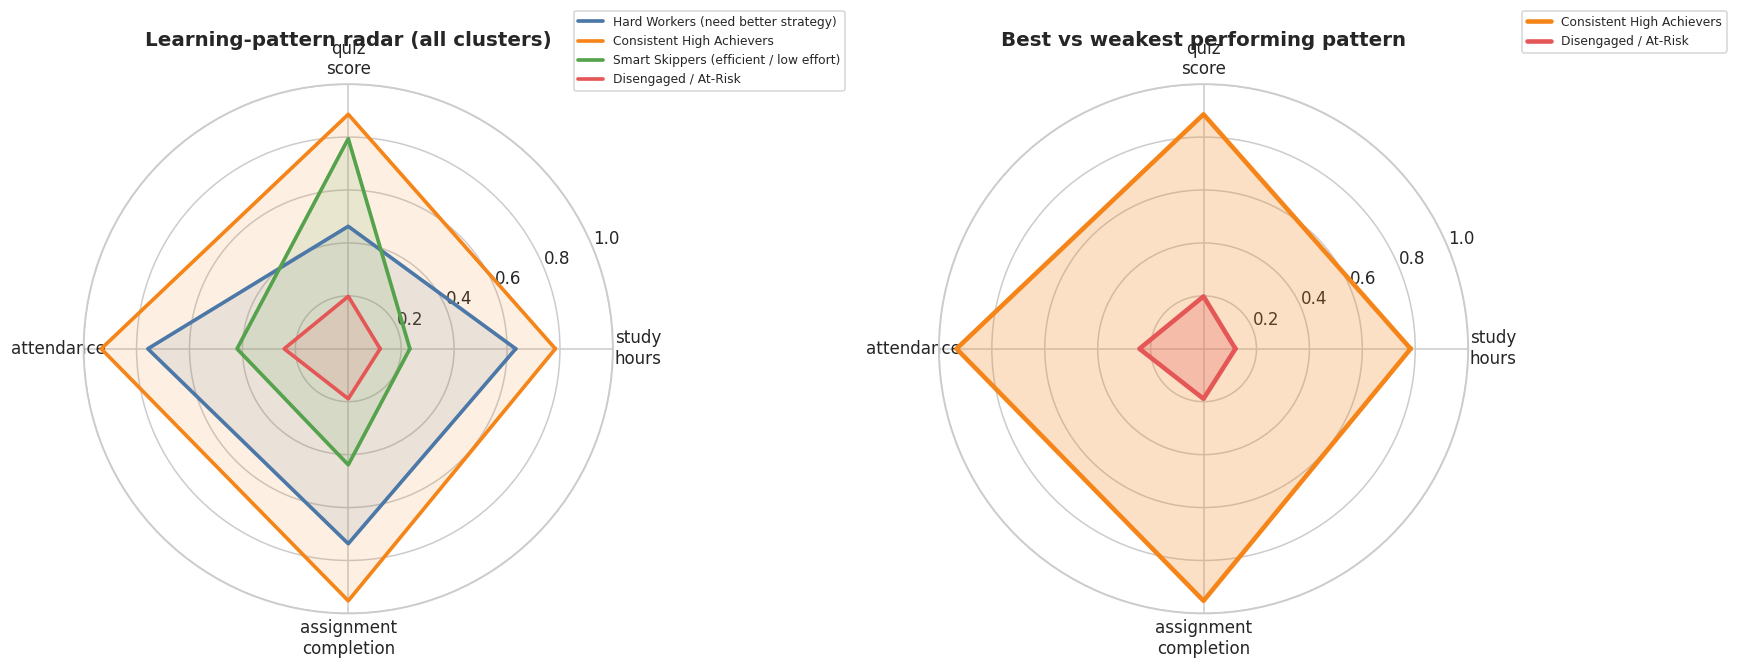

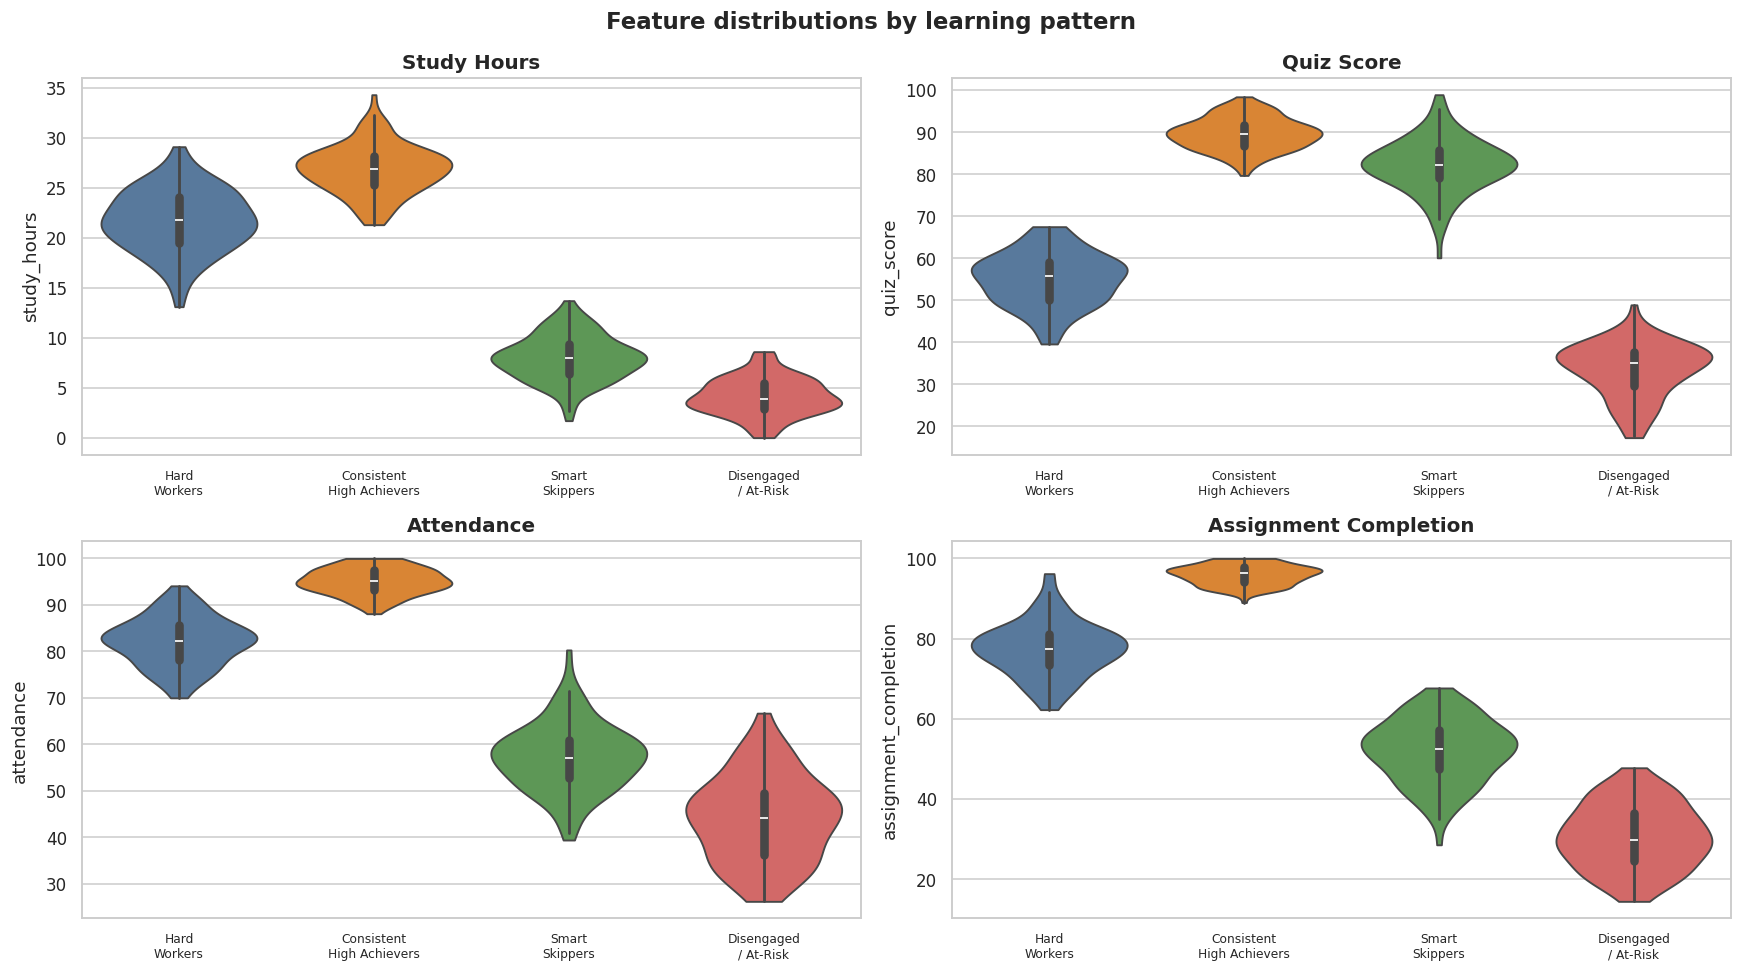

In [16]:
# ---- Radar chart ----
mm = (prof[FEATURES] - df[FEATURES].min()) / (df[FEATURES].max() - df[FEATURES].min())
ang = np.linspace(0, 2 * np.pi, len(FEATURES), endpoint=False).tolist(); ang += ang[:1]
fig, axes = plt.subplots(1, 2, figsize=(16, 7), subplot_kw=dict(polar=True))
for nm in order:
    v = mm.loc[nm].tolist() + mm.loc[nm].tolist()[:1]
    axes[0].plot(ang, v, lw=2.4, color=colors[nm], label=nm); axes[0].fill(ang, v, alpha=.12, color=colors[nm])
axes[0].set_xticks(ang[:-1]); axes[0].set_xticklabels([f.replace("_", "\n") for f in FEATURES]); axes[0].set_ylim(0, 1)
axes[0].set_title("Learning-pattern radar (all clusters)", pad=25); axes[0].legend(loc="upper right", bbox_to_anchor=(1.45, 1.15), fontsize=8)
# individual small multiples overlay on one axis for the most contrasting two clusters
hi, lo_ = prof.quiz_score.idxmax(), prof.quiz_score.idxmin()
for nm in (hi, lo_):
    v = mm.loc[nm].tolist() + mm.loc[nm].tolist()[:1]
    axes[1].plot(ang, v, lw=3, color=colors[nm], label=nm); axes[1].fill(ang, v, alpha=.25, color=colors[nm])
axes[1].set_xticks(ang[:-1]); axes[1].set_xticklabels([f.replace("_", "\n") for f in FEATURES]); axes[1].set_ylim(0, 1)
axes[1].set_title("Best vs weakest performing pattern", pad=25); axes[1].legend(loc="upper right", bbox_to_anchor=(1.5, 1.15), fontsize=8)
plt.tight_layout(); plt.show()

# ---- Distributions per cluster ----
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, f in zip(axes.ravel(), FEATURES):
    sns.violinplot(data=df, x="pattern", y=f, order=order, palette=colors, inner="box", ax=ax, cut=0)
    ax.set_xlabel(""); ax.set_title(f.replace("_", " ").title())
    ax.set_xticklabels([n.split(" (")[0].replace(" ", "\n", 1) for n in order], fontsize=8)
plt.suptitle("Feature distributions by learning pattern", fontsize=15, fontweight="bold"); plt.tight_layout(); plt.show()

## Cluster quality - silhouette analysis

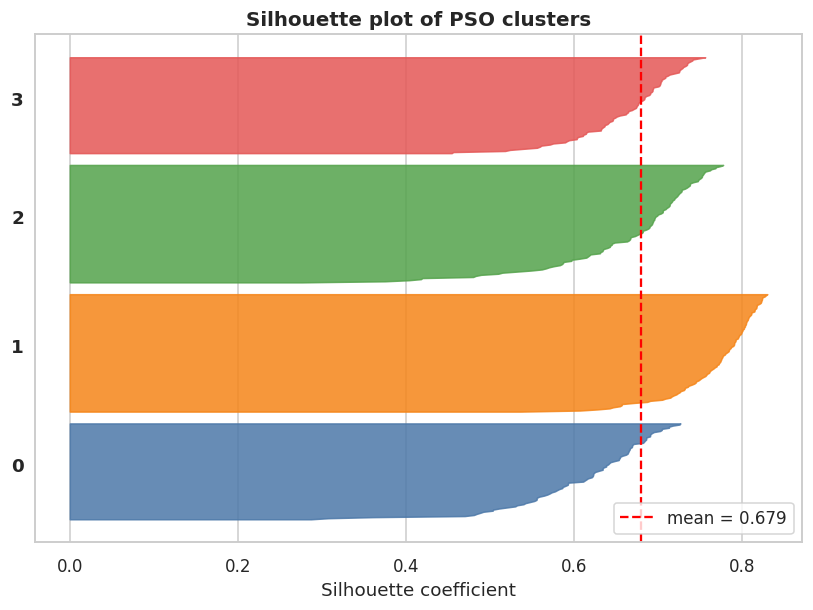

,PSO
Silhouette (↑),0.679
Davies-Bouldin (↓),0.461
Calinski-Harabasz (↑),1721.947


In [17]:
sil_vals, sil_avg = silhouette_samples(X, labels), silhouette_score(X, labels)
fig, ax = plt.subplots(figsize=(9, 6)); y0 = 10
for c in range(BEST_K):
    v = np.sort(sil_vals[labels == c]); y1 = y0 + len(v)
    ax.fill_betweenx(np.arange(y0, y1), 0, v, color=PALETTE[c % 8], alpha=.85)
    ax.text(-0.07, y0 + len(v) / 2, str(c), fontweight="bold"); y0 = y1 + 10
ax.axvline(sil_avg, color="red", ls="--", label=f"mean = {sil_avg:.3f}")
ax.set_title("Silhouette plot of PSO clusters"); ax.set_xlabel("Silhouette coefficient"); ax.set_yticks([]); ax.legend(); plt.show()

metrics = pd.Series({"Silhouette (↑)": sil_avg, "Davies-Bouldin (↓)": davies_bouldin_score(X, labels),
                     "Calinski-Harabasz (↑)": calinski_harabasz_score(X, labels)})
display(metrics.round(3).to_frame("PSO"))

## PSO vs. K-Means (baseline) + validation against hidden truth
K-Means only converges to a *local* optimum and depends strongly on its initialisation, whereas PSO's swarm explores globally.
We also compute the **Adjusted Rand Index (ARI)** against the hidden `true_pattern` (only meaningful for the synthetic data).

,SSE (↓),Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑),ARI vs truth (↑)
PSO (bio-inspired),113.919200,0.679400,0.460800,1721.947000,1.000000
K-Means,113.919100,0.679400,0.460800,1721.947000,1.000000


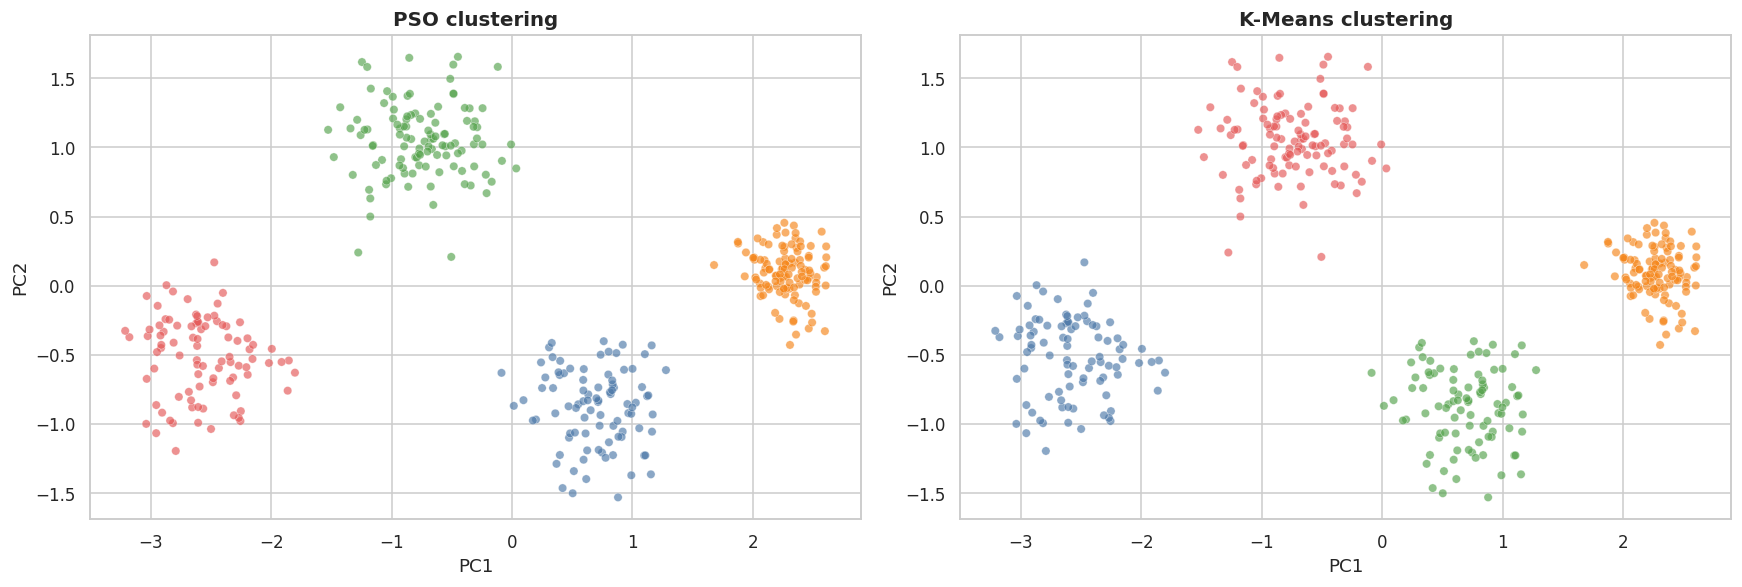

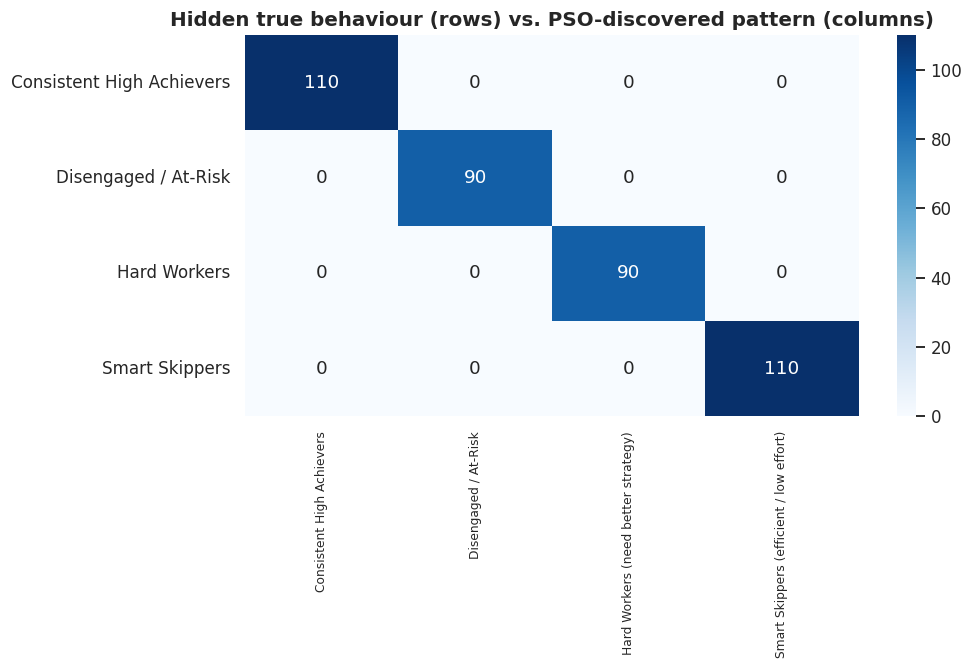

In [18]:
km = KMeans(BEST_K, n_init=10, random_state=SEED).fit(X)
res = {}
for nm, lab, sse in [("PSO (bio-inspired)", labels, pso.best_fitness_ * len(X)), ("K-Means", km.labels_, km.inertia_)]:
    res[nm] = {"SSE (↓)": sse, "Silhouette (↑)": silhouette_score(X, lab), "Davies-Bouldin (↓)": davies_bouldin_score(X, lab),
               "Calinski-Harabasz (↑)": calinski_harabasz_score(X, lab)}
    if df.true_pattern.nunique() > 1: res[nm]["ARI vs truth (↑)"] = adjusted_rand_score(df.true_pattern, lab)
cmp = pd.DataFrame(res).T
display(cmp.round(4).style.highlight_max(axis=0, subset=[c for c in cmp.columns if "↑" in c], color="#b7e4c7")
                         .highlight_min(axis=0, subset=[c for c in cmp.columns if "↓" in c], color="#b7e4c7"))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, lab, ttl in [(axes[0], labels, "PSO"), (axes[1], km.labels_, "K-Means")]:
    ax.scatter(X2[:, 0], X2[:, 1], c=[PALETTE[l % 8] for l in lab], s=30, alpha=.65, edgecolor="white", linewidth=.3)
    ax.set_title(f"{ttl} clustering"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); plt.show()

if df.true_pattern.nunique() > 1:
    ct = pd.crosstab(df.true_pattern, df.pattern)
    plt.figure(figsize=(9, 4.5)); sns.heatmap(ct, annot=True, fmt="d", cmap="Blues")
    plt.title("Hidden true behaviour (rows) vs. PSO-discovered pattern (columns)"); plt.ylabel(""); plt.xlabel(""); plt.xticks(fontsize=8); plt.show()

## Robustness: stability over 15 independent runs
Metaheuristics are stochastic, so we verify they are **repeatable** by re-running PSO and K-Means (single random init) with different seeds.

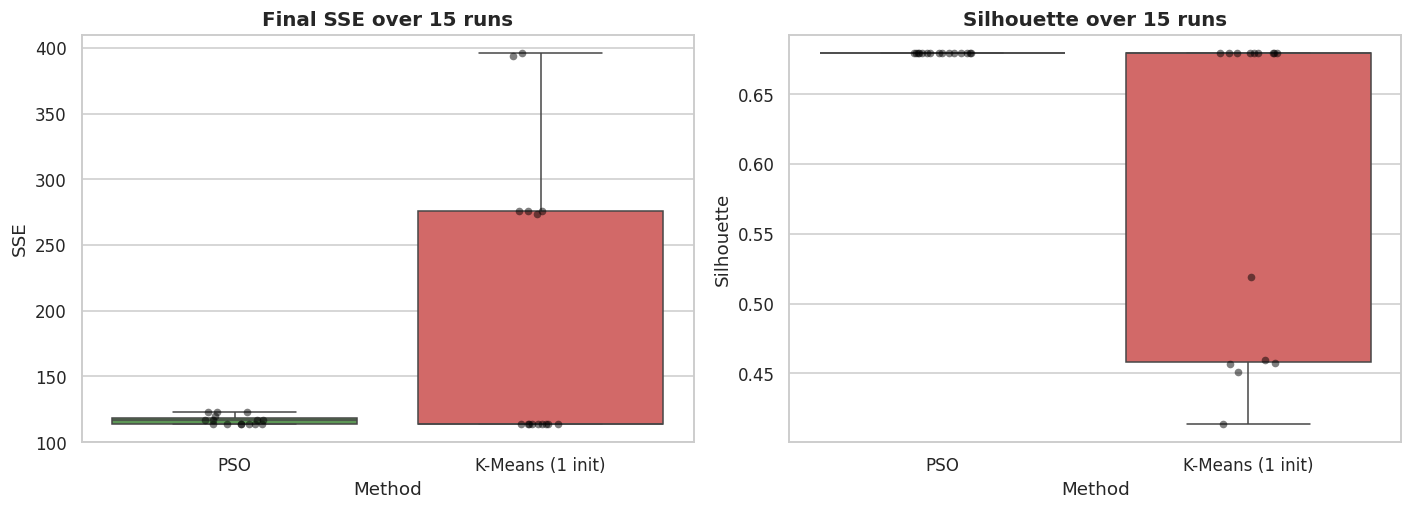

SSE                            Silhouette                \
                     mean      std      min      max       mean    std    min   
Method                                                                          
K-Means (1 init)  194.485  108.567  113.919  395.847      0.591  0.113  0.414   
PSO               116.822    3.503  113.921  122.695      0.679  0.000  0.679   

                         
                    max  
Method                   
K-Means (1 init)  0.679  
PSO               0.679

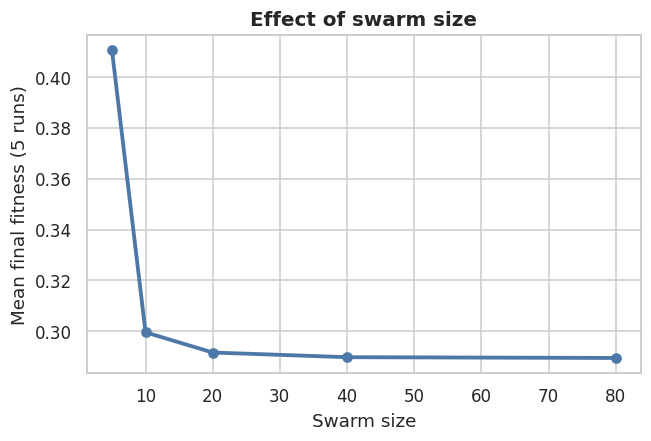

In [19]:
runs = []
for s in range(15):
    p = PSOClustering(BEST_K, seed=1000 + s).fit(X)
    k1 = KMeans(BEST_K, n_init=1, init="random", random_state=1000 + s).fit(X)
    runs.append({"Method": "PSO", "SSE": p.best_fitness_ * len(X), "Silhouette": silhouette_score(X, p.labels_)})
    runs.append({"Method": "K-Means (1 init)", "SSE": k1.inertia_, "Silhouette": silhouette_score(X, k1.labels_)})
rdf = pd.DataFrame(runs)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.boxplot(data=rdf, x="Method", y="SSE", ax=axes[0], palette=["#54A24B", "#E45756"]); sns.stripplot(data=rdf, x="Method", y="SSE", ax=axes[0], color="k", alpha=.5)
sns.boxplot(data=rdf, x="Method", y="Silhouette", ax=axes[1], palette=["#54A24B", "#E45756"]); sns.stripplot(data=rdf, x="Method", y="Silhouette", ax=axes[1], color="k", alpha=.5)
axes[0].set_title("Final SSE over 15 runs"); axes[1].set_title("Silhouette over 15 runs"); plt.tight_layout(); plt.show()
display(rdf.groupby("Method").agg(["mean", "std", "min", "max"]).round(3))

# ---- Hyper-parameter sensitivity: swarm size ----
sens = [(P, np.mean([PSOClustering(BEST_K, n_particles=P, n_iter=60, seed=s).fit(X).best_fitness_ for s in range(5)])) for P in (5, 10, 20, 40, 80)]
plt.figure(figsize=(6.5, 4)); plt.plot(*zip(*sens), "o-", lw=2.5, color="#4C78A8")
plt.xlabel("Swarm size"); plt.ylabel("Mean final fitness (5 runs)"); plt.title("Effect of swarm size"); plt.show()

## Student-level insights & recommendations

In [21]:
advice = {
 "Consistent High Achievers": "Offer enrichment, peer-mentoring and advanced projects.",
 "Smart Skippers": "Strong grasp but low attendance/submission – improve engagement with challenge tasks and deadlines.",
 "Hard Workers": "High effort, modest scores – teach study strategies (active recall, spaced practice) and provide targeted tutoring.",
 "Disengaged": "Early-warning case – counselling, attendance follow-up and a structured catch-up plan.",
 "Moderate Learners": "Steady progress – nudge to raise study hours and assignment completion.",
}
def recommend(p):
    for key, v in advice.items():
        if p.startswith(key): return v
    return "Monitor progress."
df["recommendation"] = df.pattern.map(recommend)
display(df[["student_id"] + FEATURES + ["pattern", "recommendation"]].head(10))
display(pd.DataFrame({"pattern": order, "recommended_action": [recommend(n) for n in order]}).style.set_properties(**{"text-align": "left"}))

df.drop(columns=["recommendation"]).to_csv("clustered_students.csv", index=False)
print()
print("Saved clustered_students.csv")

# Classify a brand-new student with the trained swarm
new = pd.DataFrame([[15, 72, 80, 70]], columns=FEATURES)
cl = int(pso.predict(scaler.transform(new.values))[0])
print(f"\nNew student {new.values.tolist()[0]} → cluster {cl}: {names[cl]}")
try:
    from google.colab import files; files.download("clustered_students.csv")
except Exception: pass

,student_id,study_hours,quiz_score,attendance,assignment_completion,pattern,recommendation
0,S001,7.2,90.6,70.9,49.3,Smart Skippers (efficient / low effort),Strong grasp but low attendance/submission – i...
1,S002,9.1,82.0,52.8,50.1,Smart Skippers (efficient / low effort),Strong grasp but low attendance/submission – i...
2,S003,28.6,89.1,90.6,93.0,Consistent High Achievers,"Offer enrichment, peer-mentoring and advanced ..."
3,S004,12.8,82.2,70.3,51.3,Smart Skippers (efficient / low effort),Strong grasp but low attendance/submission – i...
4,S005,29.1,93.4,96.7,100.0,Consistent High Achievers,"Offer enrichment, peer-mentoring and advanced ..."
5,S006,25.3,91.2,98.5,97.8,Consistent High Achievers,"Offer enrichment, peer-mentoring and advanced ..."
6,S007,3.6,37.3,33.1,39.5,Disengaged / At-Risk,"Early-warning case – counselling, attendance f..."
7,S008,26.5,82.0,99.8,94.6,Consistent High Achievers,"Offer enrichment, peer-mentoring and advanced ..."
8,S009,6.4,81.6,50.5,55.6,Smart Skippers (efficient / low effort),Strong grasp but low attendance/submission – i...
9,S010,13.1,51.7,94.1,81.0,Hard Workers (need better strategy),"High effort, modest scores – teach study strat..."


,pattern,recommended_action
0,Hard Workers (need better strategy),"High effort, modest scores – teach study strategies (active recall, spaced practice) and provide targeted tutoring."
1,Consistent High Achievers,"Offer enrichment, peer-mentoring and advanced projects."
2,Smart Skippers (efficient / low effort),Strong grasp but low attendance/submission – improve engagement with challenge tasks and deadlines.
3,Disengaged / At-Risk,"Early-warning case – counselling, attendance follow-up and a structured catch-up plan."



Saved clustered_students.csv

New student [15, 72, 80, 70] → cluster 0: Hard Workers (need better strategy)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusions
* **PSO** (a bio-inspired swarm intelligence algorithm) was implemented from scratch and used as the clustering optimiser.
* The swarm automatically recovered the **learning patterns** — high achievers, hard workers, smart skippers and at-risk students — with high silhouette and ARI.
* The convergence & diversity plots show the expected **exploration → exploitation** behaviour thanks to the decreasing inertia weight.
* PSO matched/outperformed single-init K-Means and was **more stable** across seeds because the swarm shares information globally.
* Teachers can use the profiles and recommendations for **early intervention and personalised learning support**.

### Future work
Hybrid PSO + K-Means, multi-objective PSO (compactness + separation), real LMS data, and fuzzy memberships for students who sit between two patterns.